# VCU Torque Analysis

This notebook loads the decoded CSV files for one `LOG####`, aligns power samples with the nearest RPM and commanded torque samples, calculates torque from power and RPM, and compares calculated and commanded torque, including rolling RMS torque over time.

## Imports

In [1]:
from pathlib import Path
import math
import re

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## User Configuration

In [2]:
# Directory containing decoded LOG####_fast.csv and LOG####_medium.csv files.
DATA_DIR = r"VCU/June11thTestingDataLog_AfterChargingBattery"

# Accepts 10, "10", "0010", or "LOG0010".
LOG_NUMBER = "LOG0012"

# Medium power samples are paired with the nearest fast torque/RPM sample within this tolerance.
MAX_MATCH_DELTA_MS = 75

# Torque from power/RPM is unstable near zero speed, so low-RPM rows are dropped.
MIN_ABS_RPM = 50

# Ratio plots drop rows where commanded torque is too close to zero.
MIN_ABS_COMMANDED_TORQUE_FOR_RATIO = 1.0

# Set to an integer to downsample the scatter plot, or leave as None to plot all valid pairs.
MAX_SCATTER_POINTS = None

# Heatmap settings for the RPM-binned torque comparison plot.
RPM_HEATMAP_BINS = 8
TORQUE_HEATMAP_BINS = 35

# RPM bins for the average torque dot plot.
AVG_TORQUE_RPM_BINS = 24

# Trailing integration window for the RMS torque vs time plot.
RMS_WINDOW_S = 1.0


## Helper Functions

In [3]:
LOG_ID_RE = re.compile(r"^LOG(?P<num>\d+)$", re.IGNORECASE)
STREAMS = ("fast", "medium", "slow", "imu")


def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in (start, *start.parents):
        if (path / "VCU").exists() and (path / "README.md").exists():
            return path
    return start


REPO_ROOT = find_repo_root()


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path

    candidates = [
        Path.cwd() / path,
        REPO_ROOT / path,
        REPO_ROOT / "VCU" / path,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    return (REPO_ROOT / path).resolve()


def format_log_id(log_number):
    text = str(log_number).strip()
    match = LOG_ID_RE.match(text)
    if match:
        number = int(match.group("num"))
    else:
        number = int(text)
    return f"LOG{number:04d}", number


def _with_elapsed_seconds(df):
    df = df.copy()
    if "t_ms" not in df.columns:
        return df

    t_ms = pd.to_numeric(df["t_ms"], errors="coerce")
    valid_t = t_ms.dropna()
    if valid_t.empty:
        return df

    df.insert(1, "elapsed_s", (t_ms - valid_t.iloc[0]) / 1000.0)
    return df


def load_single_vcu_log(data_dir, log_number, required_streams=("fast", "medium")):
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.exists():
        raise FileNotFoundError(f"Directory not found: {data_dir}")

    log_id, numeric_id = format_log_id(log_number)
    data = {}
    files = {}

    for stream in STREAMS:
        path = data_dir / f"{log_id}_{stream}.csv"
        if path.exists():
            files[stream] = path
            data[stream] = _with_elapsed_seconds(pd.read_csv(path))

    missing = [stream for stream in required_streams if stream not in data]
    if missing:
        missing_files = ", ".join(f"{log_id}_{stream}.csv" for stream in missing)
        raise FileNotFoundError(f"Missing required CSV file(s): {missing_files}")

    print(f"Loaded {log_id} from {data_dir}")
    for stream in sorted(data, key=STREAMS.index):
        print(f"  {stream}: {len(data[stream]):,} rows ({files[stream].name})")

    return {
        "log_id": log_id,
        "numeric_id": numeric_id,
        "directory": data_dir,
        "files": files,
        "data": data,
    }


def _numeric(series):
    return pd.to_numeric(series, errors="coerce")


def require_columns(df, stream, columns):
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise KeyError(f"{stream} CSV is missing required column(s): {', '.join(missing)}")


## Torque Calculation

In [4]:
def build_torque_pairs(log, max_match_delta_ms=75, min_abs_rpm=50):
    fast = log["data"]["fast"]
    medium = log["data"]["medium"]
    require_columns(fast, "fast", ["t_ms", "commanded_torque_nm", "motor_rpm"])
    require_columns(medium, "medium", ["t_ms", "power_kw"])

    fast_signals = pd.DataFrame(
        {
            "fast_t_ms": _numeric(fast["t_ms"]),
            "commanded_torque_nm": _numeric(fast["commanded_torque_nm"]),
            "motor_rpm": _numeric(fast["motor_rpm"]),
        }
    ).dropna(subset=["fast_t_ms"]).sort_values("fast_t_ms")

    medium_signals = pd.DataFrame(
        {
            "power_t_ms": _numeric(medium["t_ms"]),
            "power_kw": _numeric(medium["power_kw"]),
        }
    ).dropna(subset=["power_t_ms"]).sort_values("power_t_ms")

    aligned = pd.merge_asof(
        medium_signals,
        fast_signals,
        left_on="power_t_ms",
        right_on="fast_t_ms",
        direction="nearest",
        tolerance=max_match_delta_ms,
    )
    aligned["match_delta_ms"] = aligned["power_t_ms"] - aligned["fast_t_ms"]

    angular_velocity_rad_s = aligned["motor_rpm"] * (2.0 * math.pi / 60.0)
    aligned["calculated_torque_nm"] = (aligned["power_kw"] * 1000.0) / angular_velocity_rad_s
    aligned["torque_error_nm"] = aligned["calculated_torque_nm"] - aligned["commanded_torque_nm"]
    aligned["abs_torque_error_nm"] = aligned["torque_error_nm"].abs()

    valid = aligned[
        aligned["fast_t_ms"].notna()
        & aligned["power_kw"].notna()
        & aligned["commanded_torque_nm"].notna()
        & aligned["motor_rpm"].notna()
        & (aligned["motor_rpm"].abs() >= min_abs_rpm)
        & np.isfinite(aligned["calculated_torque_nm"])
    ].copy()

    valid["elapsed_s"] = (valid["power_t_ms"] - valid["power_t_ms"].min()) / 1000.0
    return valid.reset_index(drop=True)


def summarize_torque_pairs(torque_pairs):
    if torque_pairs.empty:
        return pd.DataFrame(
            [{"metric": "valid_pairs", "value": 0, "unit": "rows"}]
        )

    error = torque_pairs["torque_error_nm"]
    rows = [
        ("valid_pairs", len(torque_pairs), "rows"),
        ("mean_commanded_torque", torque_pairs["commanded_torque_nm"].mean(), "Nm"),
        ("max_commanded_torque", torque_pairs["commanded_torque_nm"].max(), "Nm"),
        ("mean_calculated_torque", torque_pairs["calculated_torque_nm"].mean(), "Nm"),
        ("max_calculated_torque", torque_pairs["calculated_torque_nm"].max(), "Nm"),
        ("mean_error", error.mean(), "Nm"),
        ("mean_absolute_error", error.abs().mean(), "Nm"),
        ("rmse", np.sqrt(np.mean(error ** 2)), "Nm"),
        ("correlation", torque_pairs["commanded_torque_nm"].corr(torque_pairs["calculated_torque_nm"]), ""),
    ]
    return pd.DataFrame(rows, columns=["metric", "value", "unit"])


## Plotters

In [5]:
def _scatter_sample(df, max_points=None):
    if max_points is None or len(df) <= max_points:
        return df
    return df.sample(max_points, random_state=0).sort_values("power_t_ms")


def _torque_axis_limits(torque_pairs):
    x = torque_pairs["commanded_torque_nm"]
    y = torque_pairs["calculated_torque_nm"]
    lower = min(x.min(), y.min(), 0)
    upper = max(x.max(), y.max(), 0)
    span = upper - lower
    pad = span * 0.05 if span else 1.0
    return lower - pad, upper + pad


def calculate_rms_torque_vs_time(torque_pairs, window_s=1.0):
    try:
        window_s = float(window_s)
    except (TypeError, ValueError) as exc:
        raise ValueError("window_s must be a positive number of seconds.") from exc
    if not np.isfinite(window_s) or window_s <= 0:
        raise ValueError("window_s must be a positive number of seconds.")

    torque_columns = ["commanded_torque_nm", "calculated_torque_nm"]
    required_columns = ["elapsed_s", *torque_columns]
    missing = [column for column in required_columns if column not in torque_pairs.columns]
    if missing:
        raise KeyError(f"Torque pairs are missing required column(s): {', '.join(missing)}")

    rms_df = torque_pairs[required_columns].copy()
    for column in required_columns:
        rms_df[column] = _numeric(rms_df[column])
    rms_df = (
        rms_df.replace([np.inf, -np.inf], np.nan)
        .dropna(subset=required_columns)
        .groupby("elapsed_s", as_index=False)[torque_columns].mean()
        .sort_values("elapsed_s")
        .reset_index(drop=True)
    )
    if len(rms_df) < 2:
        raise ValueError("At least two valid torque samples are required for an RMS time plot.")

    time_s = rms_df["elapsed_s"].to_numpy(dtype=float)
    window_start_s = np.maximum(time_s - window_s, time_s[0])
    integration_duration_s = time_s - window_start_s
    rms_df["integration_window_start_s"] = window_start_s
    rms_df["integration_duration_s"] = integration_duration_s

    for source_column, rms_column in (
        ("commanded_torque_nm", "commanded_torque_rms_nm"),
        ("calculated_torque_nm", "calculated_torque_rms_nm"),
    ):
        torque_squared = rms_df[source_column].to_numpy(dtype=float) ** 2
        dt_s = np.diff(time_s)
        interval_energy = 0.5 * (torque_squared[1:] + torque_squared[:-1]) * dt_s
        cumulative_energy = np.concatenate(([0.0], np.cumsum(interval_energy)))
        start_energy = np.interp(window_start_s, time_s, cumulative_energy)
        window_energy = cumulative_energy - start_energy

        rms = np.full(len(rms_df), np.nan)
        valid_duration = integration_duration_s > 0
        rms[valid_duration] = np.sqrt(
            np.maximum(window_energy[valid_duration] / integration_duration_s[valid_duration], 0.0)
        )
        rms_df[rms_column] = rms

    return rms_df


def plot_rms_torque_vs_time(torque_pairs, window_s=1.0, log_id=None):
    rms_df = calculate_rms_torque_vs_time(torque_pairs, window_s=window_s)

    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    ax.plot(
        rms_df["elapsed_s"],
        rms_df["commanded_torque_rms_nm"],
        linewidth=1.8,
        label="Commanded torque RMS",
    )
    ax.plot(
        rms_df["elapsed_s"],
        rms_df["calculated_torque_rms_nm"],
        linewidth=1.8,
        label="Calculated torque RMS",
    )

    title = f"RMS torque vs time ({float(window_s):g} s trailing integration window)"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel("RMS torque (Nm)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax, rms_df


def plot_torque_scatter(torque_pairs, log_id=None, max_points=None, color_by="motor_rpm"):
    if torque_pairs.empty:
        raise ValueError("No valid torque pairs to plot. Try lowering MIN_ABS_RPM or increasing MAX_MATCH_DELTA_MS.")

    plot_df = _scatter_sample(torque_pairs, max_points=max_points)
    x = plot_df["commanded_torque_nm"]
    y = plot_df["calculated_torque_nm"]

    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    scatter_kwargs = {"s": 22, "alpha": 0.75, "edgecolors": "none"}
    if color_by in plot_df.columns:
        points = ax.scatter(x, y, c=plot_df[color_by], cmap="viridis", **scatter_kwargs)
        cbar = fig.colorbar(points, ax=ax)
        cbar.set_label(color_by)
    else:
        ax.scatter(x, y, **scatter_kwargs)

    lower, upper = _torque_axis_limits(plot_df)
    ax.plot([lower, upper], [lower, upper], color="black", linestyle="--", linewidth=1.0, label="1:1")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

    title = "Calculated torque vs commanded torque"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Commanded torque (Nm)")
    ax.set_ylabel("Calculated torque from power/RPM (Nm)")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


def remove_outliers(df, column, lower_pct=1.0, upper_pct=97.0):
    """Remove outliers by trimming percentiles - very robust to skewed data"""
    lower_bound = df[column].quantile(lower_pct / 100)
    upper_bound = df[column].quantile(upper_pct / 100)
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]


def torque_ratio_pairs(torque_pairs, min_abs_commanded_torque=1.0):
    plot_df = torque_pairs.dropna(
        subset=["motor_rpm", "commanded_torque_nm", "calculated_torque_nm"]
    ).copy()
    if plot_df.empty:
        return plot_df

    plot_df = plot_df[plot_df["commanded_torque_nm"].abs() >= min_abs_commanded_torque].copy()
    plot_df["torque_ratio_calc_over_cmd"] = (
        plot_df["calculated_torque_nm"] / plot_df["commanded_torque_nm"]
    )
    plot_df = plot_df.replace([np.inf, -np.inf], np.nan)
    plot_df = plot_df.dropna(subset=["torque_ratio_calc_over_cmd"])
    return remove_outliers(plot_df, "torque_ratio_calc_over_cmd")


def plot_torque_ratio_vs_rpm_scatter(
    torque_pairs,
    log_id=None,
    max_points=None,
    min_abs_commanded_torque=1.0,
):
    plot_df = torque_ratio_pairs(
        torque_pairs,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if plot_df.empty:
        raise ValueError("No valid torque ratios to plot. Try lowering MIN_ABS_COMMANDED_TORQUE_FOR_RATIO.")

    plot_df = _scatter_sample(plot_df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        plot_df["motor_rpm"],
        plot_df["torque_ratio_calc_over_cmd"],
        s=22,
        alpha=0.65,
        edgecolors="none",
        label="Calculated / commanded",
    )
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="1.0 ratio")

    title = "Calculated/commanded torque ratio vs RPM"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Motor RPM")
    ax.set_ylabel("Calculated / commanded torque")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax


def average_torque_ratio_by_rpm_bin(torque_pairs, rpm_bins=24, min_abs_commanded_torque=1.0):
    plot_df = torque_ratio_pairs(
        torque_pairs,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if plot_df.empty:
        return pd.DataFrame()

    rpm_min = plot_df["motor_rpm"].min()
    rpm_max = plot_df["motor_rpm"].max()
    if rpm_max <= rpm_min:
        rpm_edges = np.array([rpm_min - 0.5, rpm_max + 0.5])
    else:
        rpm_edges = np.linspace(rpm_min, rpm_max, rpm_bins + 1)

    plot_df["rpm_bin"] = pd.cut(plot_df["motor_rpm"], bins=rpm_edges, include_lowest=True)
    grouped = plot_df.groupby("rpm_bin", observed=True).agg(
        rpm_mid=("motor_rpm", "mean"),
        avg_torque_ratio_calc_over_cmd=("torque_ratio_calc_over_cmd", "mean"),
        median_torque_ratio_calc_over_cmd=("torque_ratio_calc_over_cmd", "median"),
        samples=("motor_rpm", "size"),
    )
    return grouped.reset_index()


def plot_average_torque_ratio_by_rpm(
    torque_pairs,
    log_id=None,
    rpm_bins=24,
    min_abs_commanded_torque=1.0,
):
    avg_df = average_torque_ratio_by_rpm_bin(
        torque_pairs,
        rpm_bins=rpm_bins,
        min_abs_commanded_torque=min_abs_commanded_torque,
    )
    if avg_df.empty:
        raise ValueError("No valid torque ratios to average by RPM bin.")

    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        avg_df["rpm_mid"],
        avg_df["avg_torque_ratio_calc_over_cmd"],
        s=58,
        label="Avg calculated / commanded",
    )
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="1.0 ratio")

    title = "Average calculated/commanded torque ratio vs RPM bin"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Average motor RPM in bin")
    ax.set_ylabel("Average calculated / commanded torque")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="best")
    plt.show()
    return fig, ax, avg_df


def plot_power_vs_rpm_scatter(torque_pairs, log_id=None, max_points=None):
    plot_df = torque_pairs.dropna(subset=["motor_rpm", "power_kw"]).copy()
    if plot_df.empty:
        raise ValueError("No valid power/RPM pairs to plot.")

    plot_df = _scatter_sample(plot_df, max_points=max_points)
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    ax.scatter(
        plot_df["motor_rpm"],
        plot_df["power_kw"],
        s=22,
        alpha=0.65,
        edgecolors="none",
    )

    title = "Power vs RPM"
    if log_id:
        title = f"{log_id}: {title}"
    ax.set_title(title)
    ax.set_xlabel("Motor RPM")
    ax.set_ylabel("Power (kW)")
    ax.grid(True, alpha=0.25)
    plt.show()
    return fig, ax


def plot_torque_heatmaps_by_rpm(torque_pairs, log_id=None, rpm_bins=8, torque_bins=35):
    if torque_pairs.empty:
        raise ValueError("No valid torque pairs to plot. Try lowering MIN_ABS_RPM or increasing MAX_MATCH_DELTA_MS.")

    plot_df = torque_pairs.copy()
    plot_df["abs_motor_rpm"] = plot_df["motor_rpm"].abs()
    plot_df = plot_df.dropna(
        subset=["abs_motor_rpm", "commanded_torque_nm", "calculated_torque_nm"]
    )
    if plot_df.empty:
        raise ValueError("No rows have valid RPM, commanded torque, and calculated torque values.")

    rpm_min = plot_df["abs_motor_rpm"].min()
    rpm_max = plot_df["abs_motor_rpm"].max()
    if rpm_max <= rpm_min:
        rpm_edges = np.array([rpm_min - 0.5, rpm_max + 0.5])
    else:
        rpm_edges = np.linspace(rpm_min, rpm_max, rpm_bins + 1)

    plot_df["rpm_bin"] = pd.cut(
        plot_df["abs_motor_rpm"],
        bins=rpm_edges,
        include_lowest=True,
    )
    rpm_categories = plot_df["rpm_bin"].cat.categories
    lower, upper = _torque_axis_limits(plot_df)
    torque_edges = np.linspace(lower, upper, torque_bins + 1)

    heatmaps = []
    for rpm_bin in rpm_categories:
        bin_df = plot_df[plot_df["rpm_bin"] == rpm_bin]
        heatmap, _x_edges, _y_edges = np.histogram2d(
            bin_df["commanded_torque_nm"],
            bin_df["calculated_torque_nm"],
            bins=[torque_edges, torque_edges],
        )
        heatmaps.append((rpm_bin, bin_df, heatmap))

    ncols = 4
    nrows = math.ceil(len(heatmaps) / ncols)
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 3.7 * nrows),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).ravel()
    image = None

    for ax, (rpm_bin, bin_df, heatmap) in zip(axes, heatmaps):
        max_count = heatmap.max()
        normalized_heatmap = (heatmap / max_count * 100.0) if max_count > 0 else heatmap
        image = ax.imshow(
            normalized_heatmap.T,
            extent=[lower, upper, lower, upper],
            origin="lower",
            aspect="auto",
            cmap="afmhot",
            interpolation="bilinear",
            vmin=0,
            vmax=100,
        )
        ax.plot([lower, upper], [lower, upper], color="white", linestyle="--", linewidth=0.9)
        ax.set_title(f"{rpm_bin.left:.0f}-{rpm_bin.right:.0f} RPM | n={len(bin_df):,}")
        ax.grid(False)
        if bin_df.empty:
            ax.text(0.5, 0.5, "No samples", ha="center", va="center", transform=ax.transAxes, color="white")

    for ax in axes[len(heatmaps):]:
        ax.set_visible(False)

    for ax in axes[:len(heatmaps)]:
        ax.set_xlim(lower, upper)
        ax.set_ylim(lower, upper)
    for ax in axes[-ncols:]:
        if ax.get_visible():
            ax.set_xlabel("Commanded torque (Nm)")
    for ax in axes[::ncols]:
        if ax.get_visible():
            ax.set_ylabel("Calculated torque (Nm)")

    title = "Calculated vs commanded torque heatmap by RPM bin"
    if log_id:
        title = f"{log_id}: {title}"
    fig.suptitle(title, fontsize=14)
    if image is not None:
        fig.colorbar(image, ax=axes[:len(heatmaps)], label="Normalized bin count (%)")
    plt.show()
    return fig, axes


## Usage

In [6]:
log = load_single_vcu_log(DATA_DIR, LOG_NUMBER)
torque_pairs = build_torque_pairs(
    log,
    max_match_delta_ms=MAX_MATCH_DELTA_MS,
    min_abs_rpm=MIN_ABS_RPM,
)

display(summarize_torque_pairs(torque_pairs).round({"value": 3}))
display(torque_pairs.head())


Loaded LOG0012 from C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\BERT26-Firmware\VCU\June11thTestingDataLog_AfterChargingBattery
  fast: 95,211 rows (LOG0012_fast.csv)
  medium: 10,533 rows (LOG0012_medium.csv)
  slow: 1,066 rows (LOG0012_slow.csv)
  imu: 95,211 rows (LOG0012_imu.csv)


,metric,value,unit
0,valid_pairs,6244.000,rows
1,mean_commanded_torque,65.376,Nm
2,max_commanded_torque,210.000,Nm
3,mean_calculated_torque,56.542,Nm
4,max_calculated_torque,242.003,Nm
5,mean_error,-8.835,Nm
6,mean_absolute_error,18.557,Nm
7,rmse,37.732,Nm
8,correlation,0.883,


,power_t_ms,power_kw,fast_t_ms,commanded_torque_nm,motor_rpm,match_delta_ms,calculated_torque_nm,torque_error_nm,abs_torque_error_nm,elapsed_s
0,41262,0.1,41267,47.3,63,-5,15.157614,-32.142386,32.142386,0.000
1,41362,0.2,41364,47.3,71,-2,26.899427,-20.400573,20.400573,0.100
2,41466,0.4,41466,47.3,111,0,34.411880,-12.888120,12.888120,0.204
3,41574,0.4,41574,47.3,98,0,38.976721,-8.323279,8.323279,0.312
4,41674,0.4,41678,47.3,114,-4,33.506304,-13.793696,13.793696,0.412


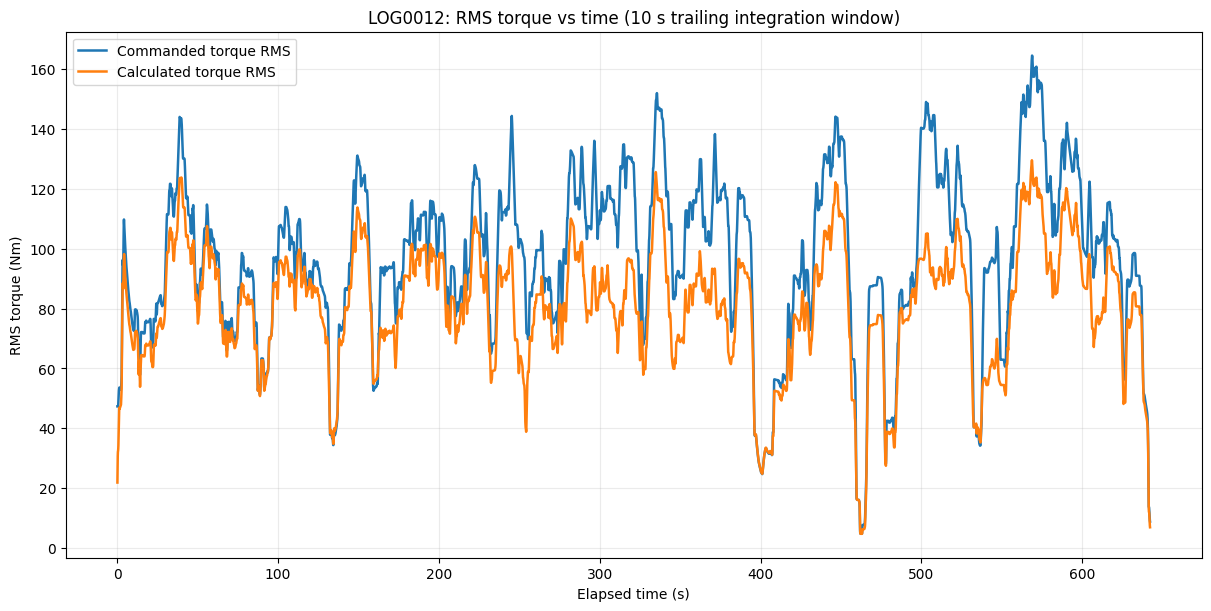

In [13]:
_fig, _ax, rms_torque_vs_time = plot_rms_torque_vs_time(
    torque_pairs,
    window_s=10,
    log_id=log["log_id"],
)

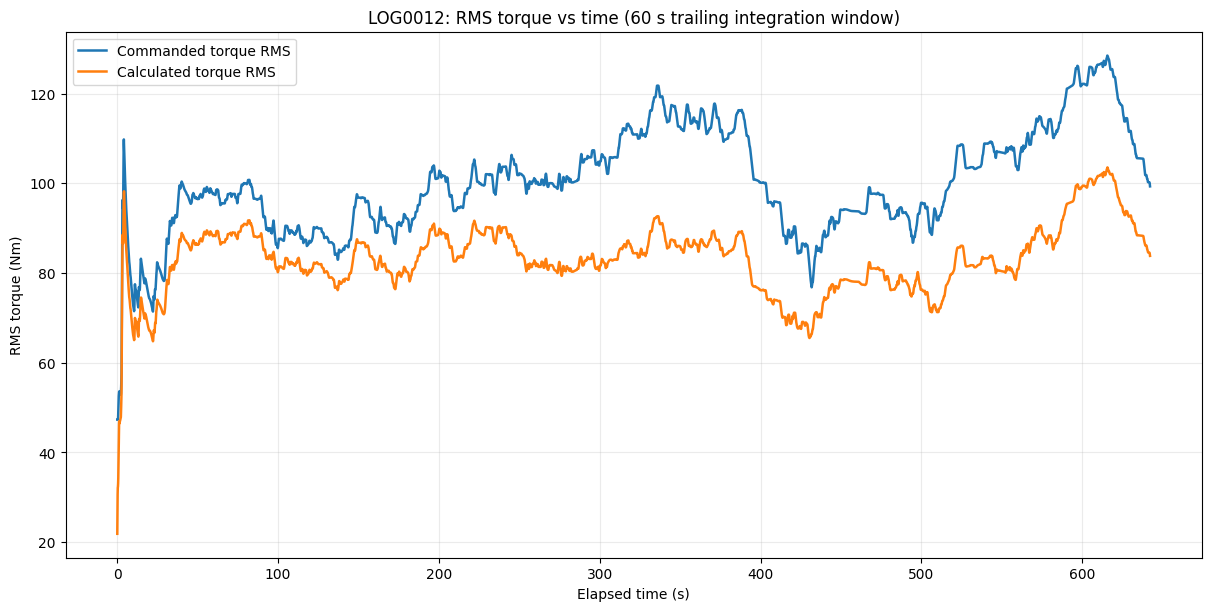

In [14]:
_fig, _ax, rms_torque_vs_time = plot_rms_torque_vs_time(
    torque_pairs,
    window_s=60,
    log_id=log["log_id"],
)

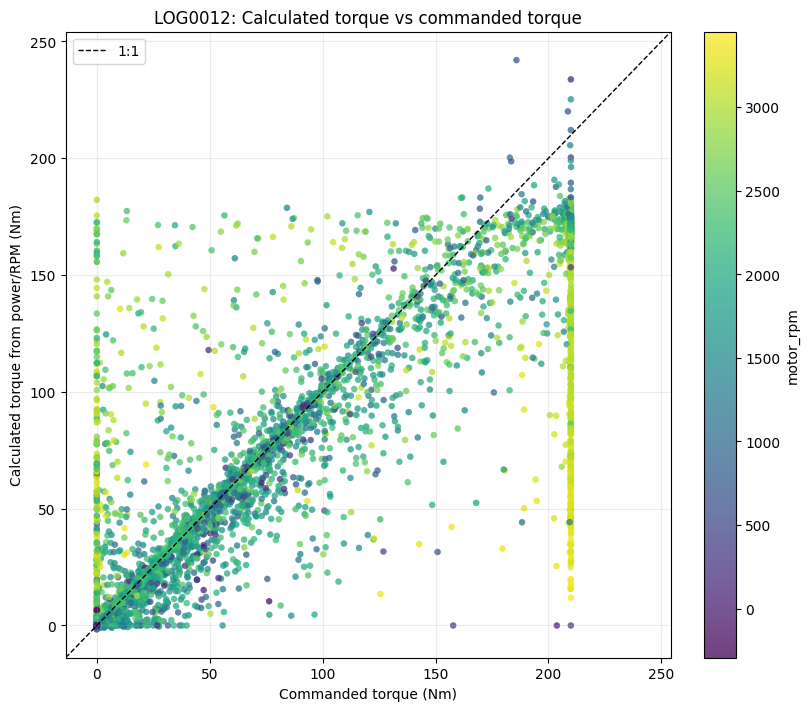

(<Figure size 800x700 with 2 Axes>,
 <AxesSubplot: title={'center': 'LOG0012: Calculated torque vs commanded torque'}, xlabel='Commanded torque (Nm)', ylabel='Calculated torque from power/RPM (Nm)'>)

In [8]:
plot_torque_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
    color_by="motor_rpm",
)


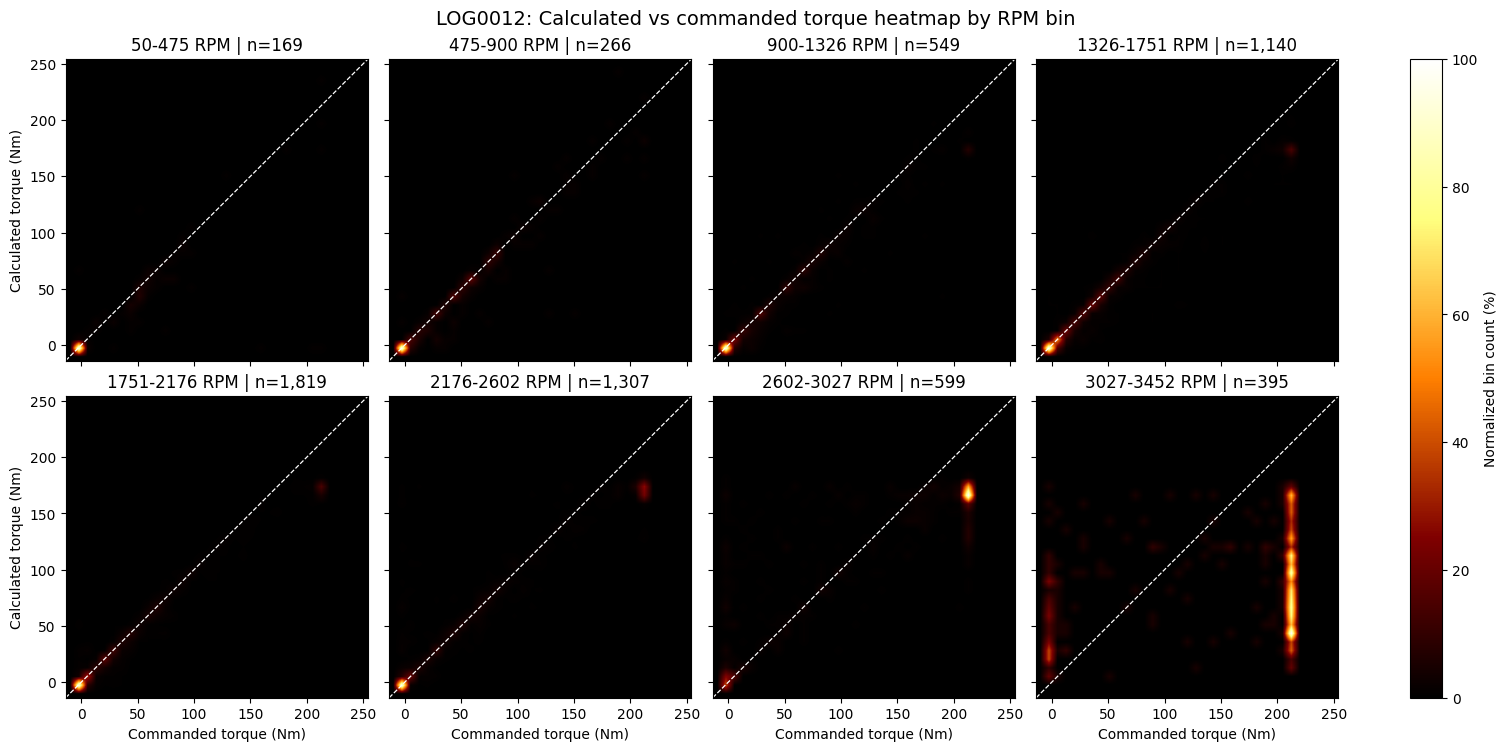

(<Figure size 1500x740 with 9 Axes>,
 array([<AxesSubplot: title={'center': '50-475 RPM | n=169'}, ylabel='Calculated torque (Nm)'>,
        <AxesSubplot: title={'center': '475-900 RPM | n=266'}>,
        <AxesSubplot: title={'center': '900-1326 RPM | n=549'}>,
        <AxesSubplot: title={'center': '1326-1751 RPM | n=1,140'}>,
        <AxesSubplot: title={'center': '1751-2176 RPM | n=1,819'}, xlabel='Commanded torque (Nm)', ylabel='Calculated torque (Nm)'>,
        <AxesSubplot: title={'center': '2176-2602 RPM | n=1,307'}, xlabel='Commanded torque (Nm)'>,
        <AxesSubplot: title={'center': '2602-3027 RPM | n=599'}, xlabel='Commanded torque (Nm)'>,
        <AxesSubplot: title={'center': '3027-3452 RPM | n=395'}, xlabel='Commanded torque (Nm)'>],
       dtype=object))

In [9]:
plot_torque_heatmaps_by_rpm(
    torque_pairs,
    log_id=log["log_id"],
    rpm_bins=RPM_HEATMAP_BINS,
    torque_bins=TORQUE_HEATMAP_BINS,
)


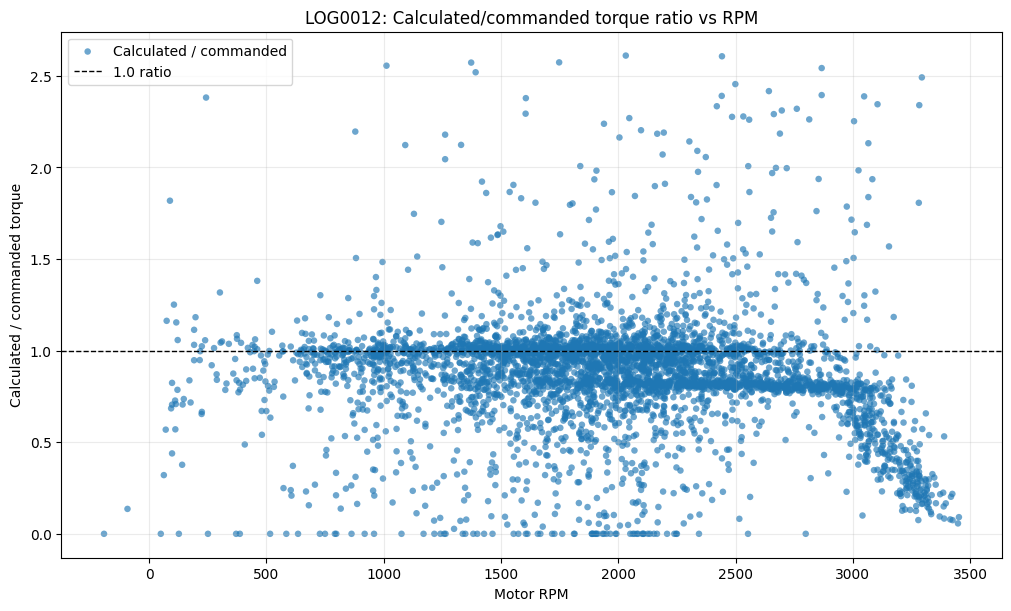

(<Figure size 1000x600 with 1 Axes>,
 <AxesSubplot: title={'center': 'LOG0012: Calculated/commanded torque ratio vs RPM'}, xlabel='Motor RPM', ylabel='Calculated / commanded torque'>)

In [10]:
plot_torque_ratio_vs_rpm_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
    min_abs_commanded_torque=MIN_ABS_COMMANDED_TORQUE_FOR_RATIO,
)


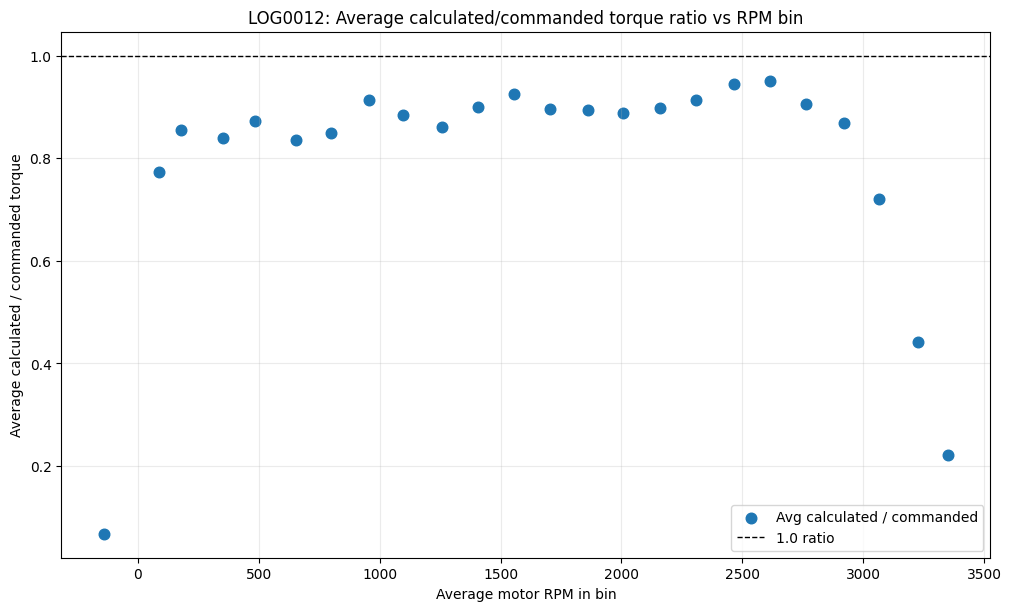

,rpm_bin,rpm_mid,avg_torque_ratio_calc_over_cmd,median_torque_ratio_calc_over_cmd,samples
0,"(-192.001, -40.167]",-142.000,0.068,0.068,2
1,"(-40.167, 111.667]",86.636,0.773,0.705,11
2,"(111.667, 263.5]",178.609,0.854,0.838,23
3,"(263.5, 415.333]",352.840,0.839,0.871,25
4,"(415.333, 567.167]",484.833,0.873,0.914,30
5,"(567.167, 719.0]",655.365,0.835,0.977,52
6,"(719.0, 870.833]",799.320,0.849,0.951,97
7,"(870.833, 1022.667]",957.459,0.913,0.967,146
8,"(1022.667, 1174.5]",1098.057,0.885,0.942,122
9,"(1174.5, 1326.333]",1259.789,0.860,0.931,123


In [11]:
_fig, _ax, avg_torque_ratio_by_rpm = plot_average_torque_ratio_by_rpm(
    torque_pairs,
    log_id=log["log_id"],
    rpm_bins=AVG_TORQUE_RPM_BINS,
    min_abs_commanded_torque=MIN_ABS_COMMANDED_TORQUE_FOR_RATIO,
)
display(avg_torque_ratio_by_rpm.round(3))


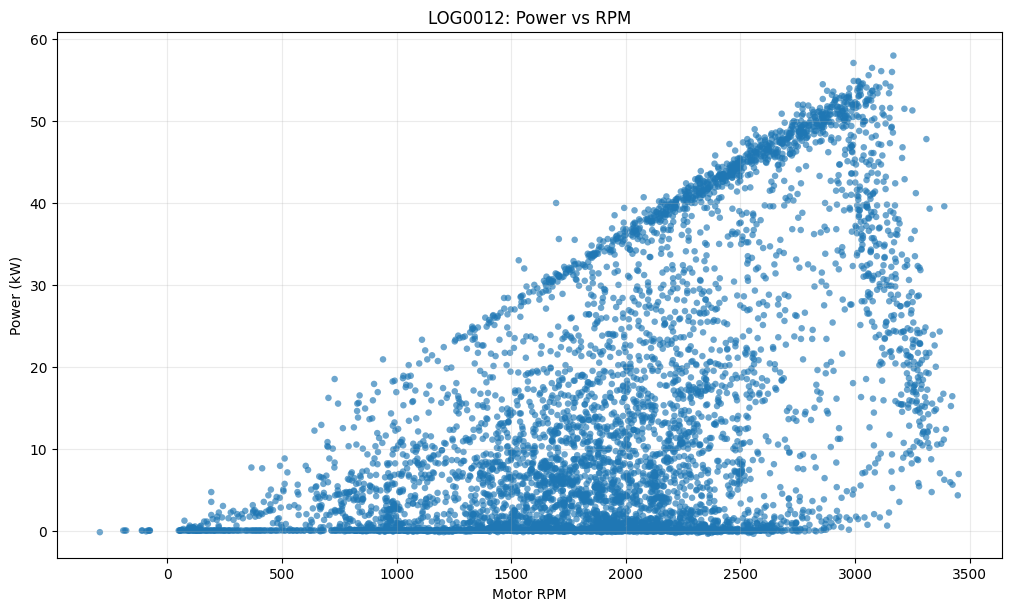

(<Figure size 1000x600 with 1 Axes>,
 <AxesSubplot: title={'center': 'LOG0012: Power vs RPM'}, xlabel='Motor RPM', ylabel='Power (kW)'>)

In [12]:
plot_power_vs_rpm_scatter(
    torque_pairs,
    log_id=log["log_id"],
    max_points=MAX_SCATTER_POINTS,
)
